# Monte Carlo Methods — A Complete Guide

**From coin flips to option pricing.** This notebook builds Monte Carlo (MC) methods
from first principles: the probability theory that makes them work, every major
*family* of technique, the *mathematics* of their error, and *applications* across
finance, physics, statistics, and optimization — all with runnable code and visuals.

---

## Table of contents

1. **Intuition & history** — what is a Monte Carlo method?
2. **Mathematical foundations** — LLN, CLT, and the $\mathcal{O}(N^{-1/2})$ error law
3. **The canonical example** — estimating $\pi$
4. **Monte Carlo integration** — the workhorse
5. **Sampling from distributions** — inverse transform & rejection sampling
6. **Variance reduction** — antithetic variates, control variates, importance & stratified sampling
7. **Quasi–Monte Carlo** — low-discrepancy sequences
8. **Markov Chain Monte Carlo (MCMC)** — Metropolis–Hastings & Bayesian inference
9. **Applications**
   - Finance: option pricing & Value-at-Risk
   - Physics: random walks / diffusion
   - Optimization: simulated annealing
10. **Convergence diagnostics & pitfalls**
11. **Cheat sheet & further reading**

In [2]:
# --- Setup -------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import scipy.stats as st

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# A single seeded generator so every run of this notebook is reproducible.
rng = np.random.default_rng(42)
print("NumPy", np.__version__, "| SciPy", st.__version__ if hasattr(st,'__version__') else 'ok')

# --- explanation helper: renders formatted text as output under a visual ---
from IPython.display import display, HTML
def explain(html):
    display(HTML('<div style="background:#f6f8fa;border-left:4px solid #2563eb;padding:10px 14px;margin-top:6px;border-radius:6px;font-size:14px;line-height:1.55;color:#1f2937">' + html + '</div>'))

NumPy 2.5.0 | SciPy ok


## 1. Intuition & history

A **Monte Carlo method** answers a deterministic question using **random sampling**.
Instead of solving an integral, a PDE, or a combinatorial sum *exactly*, we:

1. Express the quantity we want as the **expected value** of some random variable,
   $\;\mu = \mathbb{E}[g(X)]$.
2. Draw many independent samples $X_1, \dots, X_N$.
3. Estimate $\mu$ by the **sample average** $\;\hat\mu_N = \frac{1}{N}\sum_{i=1}^N g(X_i)$.

The name comes from the **Monte Carlo casino** in Monaco. The modern method was
invented in the 1940s by **Stanislaw Ulam** and **John von Neumann** at Los Alamos
while working on neutron diffusion for nuclear weapons — Ulam reportedly got the idea
while playing solitaire and wondering about the *probability* of winning, realizing
simulation beat combinatorics.

> **The big idea:** *Hard deterministic problems become easy averaging problems if you
> can phrase them as an expectation and sample from the right distribution.*

This works in **any dimension** and is the reason MC dominates high-dimensional
integration where classical quadrature collapses (the "curse of dimensionality").

## 2. Mathematical foundations

Two theorems guarantee Monte Carlo works.

### Law of Large Numbers (LLN) — *why the estimate is correct*

If $X_1, X_2, \dots$ are i.i.d. with finite mean $\mu = \mathbb{E}[g(X)]$, then the
sample mean converges to the true mean:

$$\hat\mu_N = \frac{1}{N}\sum_{i=1}^N g(X_i) \;\xrightarrow[N\to\infty]{\text{a.s.}}\; \mu .$$

So the estimator is **consistent** — more samples ⇒ closer to the truth.

### Central Limit Theorem (CLT) — *how fast, and how uncertain*

Let $\sigma^2 = \operatorname{Var}[g(X)] < \infty$. Then the error is asymptotically
**Gaussian**:

$$\sqrt{N}\,(\hat\mu_N - \mu) \;\xrightarrow{d}\; \mathcal{N}(0, \sigma^2).$$

Equivalently the **standard error** of the estimate is

$$\operatorname{SE}(\hat\mu_N) = \frac{\sigma}{\sqrt{N}} .$$

### The defining feature: $\mathcal{O}(N^{-1/2})$ convergence

The error shrinks like $1/\sqrt{N}$ **regardless of dimension** $d$. To gain one
extra decimal digit of accuracy you need **100× more samples**. Compare with classical
grid methods:

| Method | Error in $d$ dimensions |
|---|---|
| Trapezoid rule (grid) | $\mathcal{O}(N^{-2/d})$ — **dies** as $d$ grows |
| **Monte Carlo** | $\mathcal{O}(N^{-1/2})$ — **independent of $d$** |
| Quasi–Monte Carlo | $\mathcal{O}((\log N)^d / N)$ — near $N^{-1}$ |

MC's slow-but-dimension-blind rate is exactly why it wins in high dimensions. We
verify the $1/\sqrt{N}$ law empirically below.

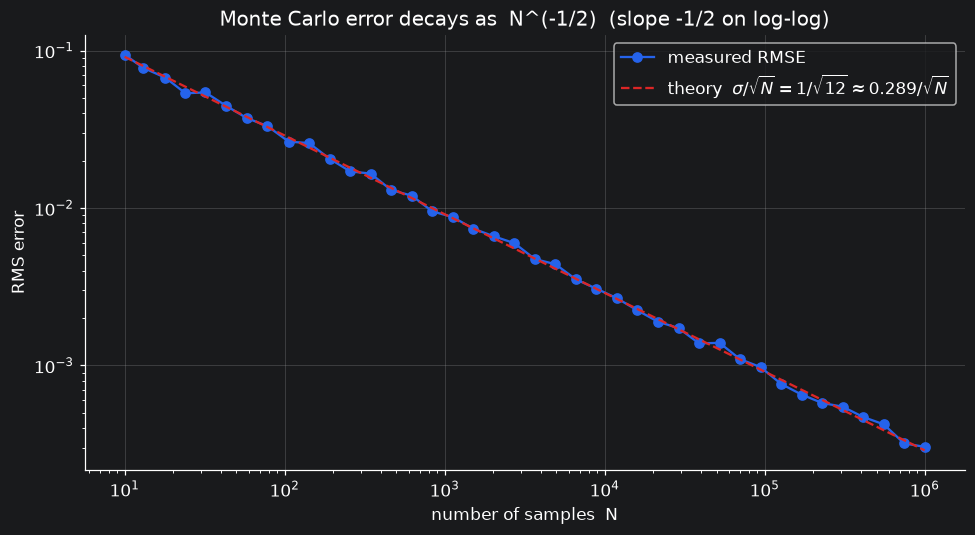

Fitted log-log slope = -0.498   (theory = -0.5)


In [2]:
# Empirically confirm the O(1/sqrt(N)) error law.
# Estimate mu = E[X] for X ~ Uniform(0,1), whose true mean is 0.5.
true_mu = 0.5
Ns = np.logspace(1, 6, 40).astype(int)          # 10 ... 1,000,000 samples
trials = 200                                      # repeat to measure the *spread* of error

rng_local = np.random.default_rng(0)
errors = np.empty((len(Ns), trials))
for i, N in enumerate(Ns):
    samples = rng_local.random((trials, N))       # (trials, N) uniforms
    errors[i] = np.abs(samples.mean(axis=1) - true_mu)

rmse = np.sqrt((errors**2).mean(axis=1))          # root-mean-square error per N

fig, ax = plt.subplots()
ax.loglog(Ns, rmse, "o-", label="measured RMSE", color="#2563eb")
ax.loglog(Ns, (1/np.sqrt(12))*Ns**-0.5, "--", color="#dc2626",
          label=r"theory $\;\sigma/\sqrt{N}=1/\sqrt{12}\approx 0.289/\sqrt{N}$")
ax.set(xlabel="number of samples  N", ylabel="RMS error",
       title="Monte Carlo error decays as  N^(-1/2)  (slope -1/2 on log-log)")
ax.legend()
plt.tight_layout(); plt.show()

slope = np.polyfit(np.log(Ns), np.log(rmse), 1)[0]
print(f"Fitted log-log slope = {slope:.3f}   (theory = -0.5)")

explain(r'''
<b>How to read this.</b> Both axes are logarithmic, so a power law plots as a straight line; the measured error (blue) sits on the theoretical &sigma;/&radic;N line (red) and the fitted slope is &asymp; &minus;0.5.<br><b>Takeaway:</b> Monte&nbsp;Carlo error shrinks like 1/&radic;N &mdash; one extra decimal digit costs <b>100&times; more samples</b>, independent of dimension.
''')

## 3. The canonical example — estimating $\pi$

The "hello world" of Monte Carlo. Throw random darts at the unit square
$[0,1]^2$ and count how many land inside the quarter circle of radius 1.

The probability a uniform point lands inside is the **area ratio**:

$$P(\text{inside}) = \frac{\text{area of quarter circle}}{\text{area of square}}
= \frac{\pi/4}{1} = \frac{\pi}{4}.$$

So $\;\hat\pi = 4 \times \dfrac{\#\{\text{points inside}\}}{N}.$ This is a Monte Carlo
*estimate of an integral* in disguise — the integral being the area.

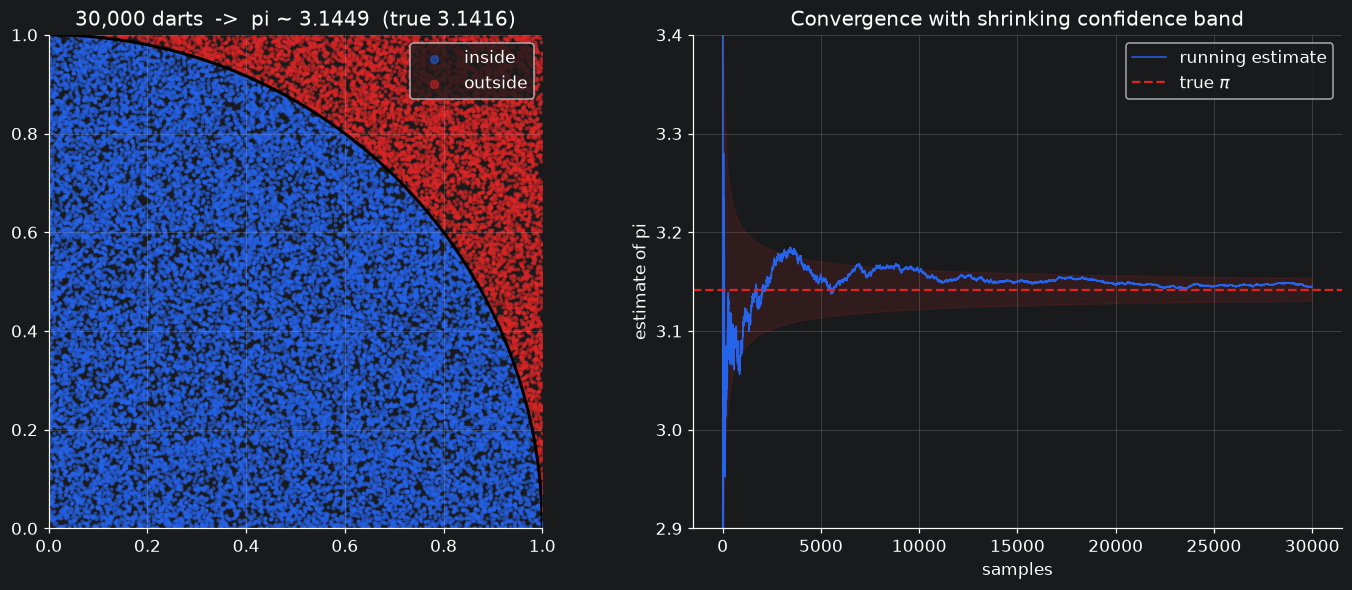

pi estimate = 3.14493  +/-  0.01856  (95% CI), true = 3.14159


In [3]:
N = 30_000
pts = rng.random((N, 2))
inside = (pts[:, 0]**2 + pts[:, 1]**2) <= 1.0
pi_est = 4 * inside.mean()
se = 4 * np.sqrt(inside.mean()*(1-inside.mean())/N)   # binomial standard error

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5.5))

# Left: the dartboard
axL.scatter(*pts[inside].T,  s=3, color="#2563eb", alpha=0.5, label="inside")
axL.scatter(*pts[~inside].T, s=3, color="#dc2626", alpha=0.5, label="outside")
theta = np.linspace(0, np.pi/2, 300)
axL.plot(np.cos(theta), np.sin(theta), "k", lw=2)
axL.set(xlim=(0,1), ylim=(0,1), aspect="equal",
        title=f"{N:,} darts  ->  pi ~ {pi_est:.4f}  (true {np.pi:.4f})")
axL.legend(loc="upper right", markerscale=3)

# Right: running estimate converging to pi
running = 4 * np.cumsum(inside) / np.arange(1, N+1)
axR.plot(running, color="#2563eb", lw=1, label="running estimate")
axR.axhline(np.pi, color="#dc2626", ls="--", label=r"true $\pi$")
band = 4*np.sqrt(0.25/np.arange(1,N+1))               # rough +/- shrinking band
axR.fill_between(np.arange(N), np.pi-band, np.pi+band, color="#dc2626", alpha=0.12)
axR.set(xlabel="samples", ylabel="estimate of pi", ylim=(2.9, 3.4),
        title="Convergence with shrinking confidence band")
axR.legend()
plt.tight_layout(); plt.show()

print(f"pi estimate = {pi_est:.5f}  +/-  {1.96*se:.5f}  (95% CI), true = {np.pi:.5f}")

explain(r'''
<b>How to read this.</b> <i>Left:</i> 30,000 random darts &mdash; blue landed inside the quarter circle, red outside. Since the quarter circle covers &pi;/4 of the square, &pi; &asymp; 4 &times; inside/total. <i>Right:</i> the running estimate with its shrinking 95% confidence band around the true value (dashed).<br><b>Takeaway:</b> noisy early, tightening as 1/&radic;N &mdash; Monte&nbsp;Carlo integration in its simplest form.
''')

### 3.1  Animated companion — watch $\pi$ emerge

The cell below embeds a Manim-rendered animation of exactly this experiment: random darts rain into the unit square (blue = inside the quarter circle, red = outside), while the live estimate $\hat\pi = 4\times\frac{\text{inside}}{\text{total}}$ converges toward the true value of $\pi$ on the number line. It is the dynamic version of the two static plots above.

In [1]:
# Embedded animation of Monte Carlo pi estimation (rendered with Manim).

from IPython.display import Video
display(Video("media/videos/monte_carlo_pi/1080p60/MonteCarloPi.mp4",
      embed=True, width=900, html_attributes="controls loop"))

## 4. Monte Carlo integration — the workhorse

The most important use of MC. To compute a definite integral

$$I = \int_a^b f(x)\,dx,$$

rewrite it as an expectation under the uniform density on $[a,b]$ (which has
density $\tfrac{1}{b-a}$):

$$I = (b-a)\,\mathbb{E}_{X\sim U(a,b)}\!\big[f(X)\big]
\;\approx\; \frac{b-a}{N}\sum_{i=1}^N f(X_i).$$

This generalizes immediately to $d$ dimensions over a region of volume $V$:

$$\int_\Omega f\,dV \approx \frac{V}{N}\sum_{i=1}^N f(X_i),\qquad X_i \sim U(\Omega).$$

We test it on $\int_0^1 e^{-x^2}\,dx$ (no elementary antiderivative — it equals
$\tfrac{\sqrt\pi}{2}\operatorname{erf}(1)$), and on a **6-dimensional** integral to
show MC shrugs off dimensionality.

1-D MC : 0.746458 +/- 0.001246   true = 0.746824
6-D MC : 1.000616   true = 1.000000   (V=15.022)


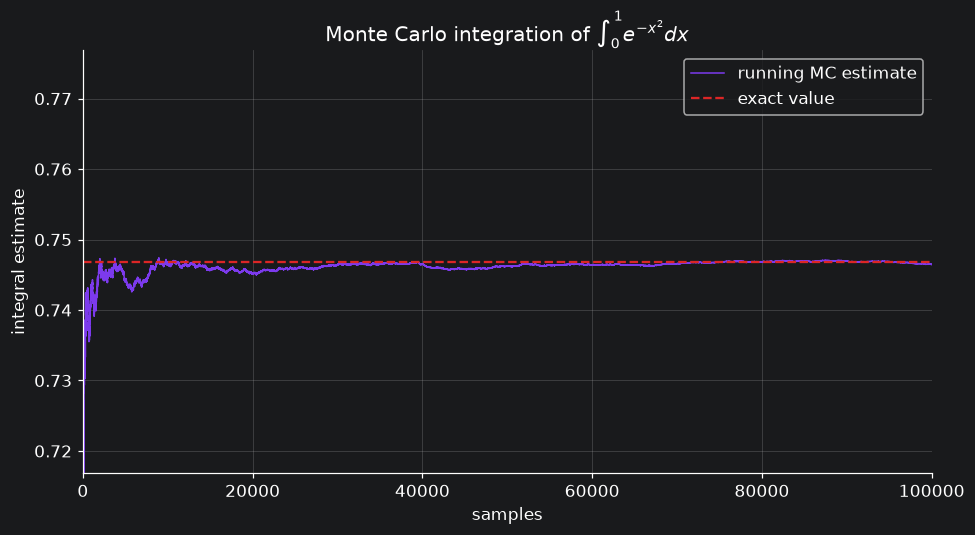

In [5]:
# 1-D: integral of exp(-x^2) over [0,1]
f = lambda x: np.exp(-x**2)
from scipy.special import erf
true_val = np.sqrt(np.pi)/2 * erf(1)          # exact value of the integral

N = 100_000
x = rng.random(N)
mc_val = f(x).mean()                 # (b-a)=1
mc_se  = f(x).std(ddof=1)/np.sqrt(N)
print(f"1-D MC : {mc_val:.6f} +/- {1.96*mc_se:.6f}   true = {true_val:.6f}")

# 6-D: integral of prod(cos(x_i)) over [0, pi/2]^6 ; exact value = 1
d, N6 = 6, 500_000
X = rng.random((N6, d)) * (np.pi/2)
vals = np.cos(X).prod(axis=1)
V = (np.pi/2)**d
mc6 = V * vals.mean()
print(f"6-D MC : {mc6:.6f}   true = 1.000000   (V={V:.3f})")

# Visual: shrinking estimate vs samples for the 1-D case
run = np.cumsum(f(x))/np.arange(1, N+1)
plt.figure()
plt.plot(run, lw=1, color="#7c3aed", label="running MC estimate")
plt.axhline(true_val, color="#dc2626", ls="--", label="exact value")
plt.xlim(0, N); plt.ylim(true_val-0.03, true_val+0.03)
plt.xlabel("samples"); plt.ylabel("integral estimate")
plt.title(r"Monte Carlo integration of $\int_0^1 e^{-x^2}dx$")
plt.legend(); plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> The purple line is the MC estimate of &int;<sub>0</sub><sup>1</sup> e<sup>&minus;x&sup2;</sup> dx as samples accumulate; the dashed line is the exact value. MC integration just averages the integrand at random points.<br><b>Takeaway:</b> it converges without any antiderivative &mdash; essential here, since e<sup>&minus;x&sup2;</sup> has none in elementary form. The same trick handled the 6-D integral (MC ignores dimension).
''')

## 5. Sampling from distributions

MC needs samples from a target distribution. Two foundational engines turn the
uniform random numbers a computer gives you into samples from *any* distribution.

### 5.1 Inverse transform sampling

If $U \sim \text{Uniform}(0,1)$ and $F$ is a CDF with inverse $F^{-1}$ (the quantile
function), then

$$X = F^{-1}(U) \;\sim\; F.$$

*Proof:* $P(X \le x) = P(F^{-1}(U)\le x) = P(U \le F(x)) = F(x).$ ∎

Example: the **exponential** distribution has $F(x)=1-e^{-\lambda x}$, so
$F^{-1}(u) = -\tfrac{1}{\lambda}\ln(1-u)$.

### 5.2 Rejection sampling

When you *can't* invert $F$, wrap the target density $p(x)$ under an easy-to-sample
**proposal** $q(x)$ scaled so $p(x) \le M\,q(x)$ everywhere. Draw $X\sim q$, accept it
with probability $\dfrac{p(X)}{M\,q(X)}$. Accepted samples are exactly distributed as
$p$. The acceptance rate is $1/M$, so a tight envelope is efficient.

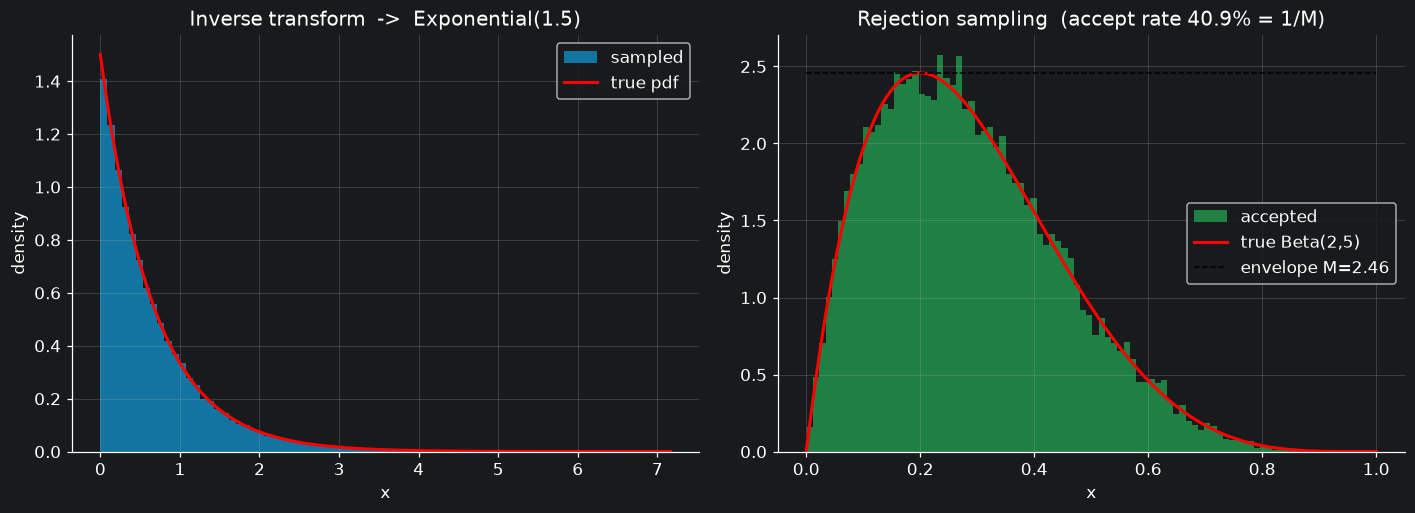

In [6]:
# --- Inverse transform: Exponential(lambda=1.5) ------------------------------
lam = 1.5
U = rng.random(50_000)
X_exp = -np.log(1 - U) / lam

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
a1.hist(X_exp, bins=80, density=True, color="#0ea5e9", alpha=0.65, label="sampled")
xx = np.linspace(0, X_exp.max(), 300)
a1.plot(xx, lam*np.exp(-lam*xx), "r", lw=2, label="true pdf")
a1.set(title="Inverse transform  ->  Exponential(1.5)", xlabel="x", ylabel="density")
a1.legend()

# --- Rejection sampling: target = Beta(2,5) using Uniform proposal -----------
a, b = 2, 5
p = lambda x: st.beta(a, b).pdf(x)
M = st.beta(a, b).pdf((a-1)/(a+b-2))            # peak height = tightest constant for U(0,1)
n_try = 60_000
xs = rng.random(n_try)                           # proposal U(0,1)
us = rng.random(n_try)
accept = us < p(xs) / (M * 1.0)
X_beta = xs[accept]

a2.hist(X_beta, bins=80, density=True, color="#22c55e", alpha=0.6, label="accepted")
xx = np.linspace(0, 1, 300)
a2.plot(xx, p(xx), "r", lw=2, label="true Beta(2,5)")
a2.plot(xx, M*np.ones_like(xx), "k--", lw=1, label=f"envelope M={M:.2f}")
a2.set(title=f"Rejection sampling  (accept rate {accept.mean():.1%} = 1/M)",
       xlabel="x", ylabel="density")
a2.legend()
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> <i>Left:</i> pushing uniform numbers through the inverse CDF F<sup>&minus;1</sup> reproduces the exponential density (red) exactly. <i>Right:</i> rejection sampling keeps only points falling under the target Beta(2,5) curve; the acceptance rate equals 1/M (the envelope height).<br><b>Takeaway:</b> these two engines turn a plain uniform RNG into samples from any distribution.
''')

## 6. Variance reduction — getting more accuracy per sample

Since error $= \sigma/\sqrt{N}$, you improve accuracy by either raising $N$ (expensive)
or **lowering the variance $\sigma^2$** of the estimator. These techniques can cut
variance by 10–1000× *for free*.

### 6.1 Antithetic variates
For each sample $U$ also use its mirror $1-U$. If $f$ is monotone, $f(U)$ and $f(1-U)$
are **negatively correlated**, so their average has lower variance:
$$\operatorname{Var}\!\left[\tfrac{f(U)+f(1-U)}{2}\right]
= \tfrac{1}{2}\big(\operatorname{Var} f + \operatorname{Cov}(f(U),f(1-U))\big).$$

### 6.2 Control variates
Subtract a correlated quantity $h(X)$ with **known** mean $\mathbb{E}[h]$:
$$\hat\mu_{cv} = \overline{f(X)} - c\,\big(\overline{h(X)} - \mathbb{E}[h]\big),
\qquad c^\star = \frac{\operatorname{Cov}(f,h)}{\operatorname{Var}(h)}.$$
The optimal $c^\star$ removes the part of $f$'s noise explained by $h$, reducing
variance by a factor $1/(1-\rho^2)$ where $\rho=\operatorname{Corr}(f,h)$.

### 6.3 Importance sampling
Sample from a cleverly chosen $q$ instead of $p$, reweighting by the **likelihood ratio**:
$$\mathbb{E}_p[f(X)] = \mathbb{E}_q\!\left[f(X)\frac{p(X)}{q(X)}\right]
\approx \frac{1}{N}\sum_i f(X_i)\frac{p(X_i)}{q(X_i)},\quad X_i\sim q.$$
Put $q$'s mass where $|f|\,p$ is large — essential for **rare events** (tail
probabilities) where naive MC almost never sees the event.

### 6.4 Stratified sampling
Split the domain into $K$ strata and sample each separately. Removes between-stratum
variance; can never do worse than plain MC.

We demonstrate antithetic + control variates on $\int_0^1 e^x dx = e-1$.

Method                  mean     std err   var reduction
Plain MC             1.71836    0.003444            1.0x
Antithetic           1.71831    0.000602           32.7x
Control variate      1.71826    0.000429           64.4x

True value = 1.71828


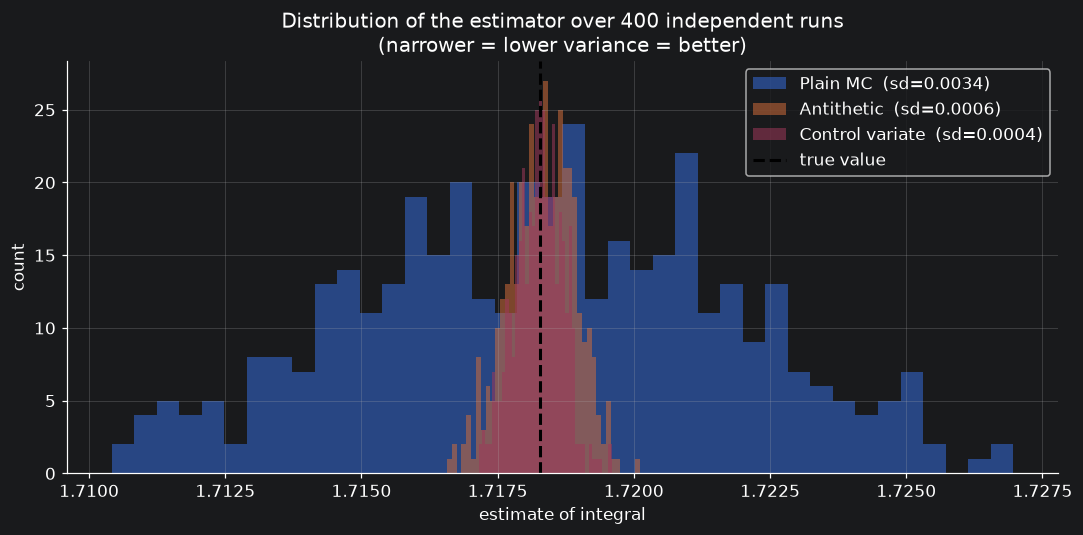

In [7]:
true = np.e - 1
N = 20_000
trials = 400
g = np.exp

def plain(rng):       # standard MC
    u = rng.random(N); return g(u).mean()

def antithetic(rng):  # use U and 1-U
    u = rng.random(N//2)
    return 0.5*(g(u) + g(1-u)).mean()

def control(rng):     # control variate h(x)=x, E[h]=0.5
    u = rng.random(N)
    fu, hu = g(u), u
    c = np.cov(fu, hu)[0,1] / np.var(hu)
    return fu.mean() - c*(hu.mean() - 0.5)

seeds = np.random.SeedSequence(7).spawn(trials)
res = {name: np.array([fn(np.random.default_rng(s)) for s in seeds])
       for name, fn in [("Plain MC", plain), ("Antithetic", antithetic),
                         ("Control variate", control)]}

print(f"{'Method':<18}{'mean':>10}{'std err':>12}{'var reduction':>16}")
base = res["Plain MC"].std()
for name, arr in res.items():
    print(f"{name:<18}{arr.mean():>10.5f}{arr.std():>12.6f}{(base/arr.std())**2:>15.1f}x")
print(f"\nTrue value = {true:.5f}")

plt.figure(figsize=(10,5))
for name, arr in res.items():
    plt.hist(arr, bins=40, alpha=0.55, label=f"{name}  (sd={arr.std():.4f})")
plt.axvline(true, color="k", ls="--", lw=2, label="true value")
plt.title("Distribution of the estimator over 400 independent runs\n"
          "(narrower = lower variance = better)")
plt.xlabel("estimate of integral"); plt.ylabel("count"); plt.legend()
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> Each histogram is the spread of the estimate over 400 independent runs. All center on the true value (dashed), but <b>narrower = lower variance = better</b>. Antithetic and control-variate estimators are visibly tighter than plain MC for the same budget.<br><b>Takeaway:</b> variance reduction buys accuracy for free. (The printed table shows the exact reduction factors.)
''')

In [8]:
# Importance sampling for a RARE-EVENT tail probability:  P(Z > 4) for Z ~ N(0,1).
# Naive MC almost never sees Z>4, so its estimate is dominated by zeros.
true_tail = st.norm.sf(4)            # ~3.17e-5
N = 200_000

# Naive
z = rng.standard_normal(N)
naive = (z > 4).mean()
naive_se = (z > 4).std()/np.sqrt(N)

# Importance sampling: shift the proposal mean to 4 so the event is common.
q = st.norm(loc=4, scale=1)
xs = q.rvs(N, random_state=rng)
w = st.norm.pdf(xs)/q.pdf(xs)        # likelihood ratio p/q
is_est = (w * (xs > 4)).mean()
is_se  = (w * (xs > 4)).std()/np.sqrt(N)

print(f"True  P(Z>4)        = {true_tail:.3e}")
print(f"Naive MC            = {naive:.3e}  +/- {1.96*naive_se:.1e}   (hits: {(z>4).sum()})")
print(f"Importance sampling = {is_est:.3e}  +/- {1.96*is_se:.1e}")
print(f"\nVariance reduction  ~ {(naive_se/is_se)**2:,.0f}x")

True  P(Z>4)        = 3.167e-05
Naive MC            = 2.000e-05  +/- 2.0e-05   (hits: 4)
Importance sampling = 3.191e-05  +/- 3.0e-07

Variance reduction  ~ 4,388x


## 7. Quasi–Monte Carlo (QMC)

Plain MC uses *random* points, which clump and leave gaps (discrepancy). **Quasi-MC**
instead uses deterministic **low-discrepancy sequences** (Sobol', Halton) that fill
space far more evenly. The integration error improves from $\mathcal{O}(N^{-1/2})$ to
roughly

$$\mathcal{O}\!\left(\frac{(\log N)^d}{N}\right)\approx \mathcal{O}(N^{-1}),$$

i.e. *nearly one full power faster* — a huge win for smooth, moderate-dimension
integrands. The trade-off: points are correlated, so classical CLT error bars don't
apply directly (use randomized QMC for that).

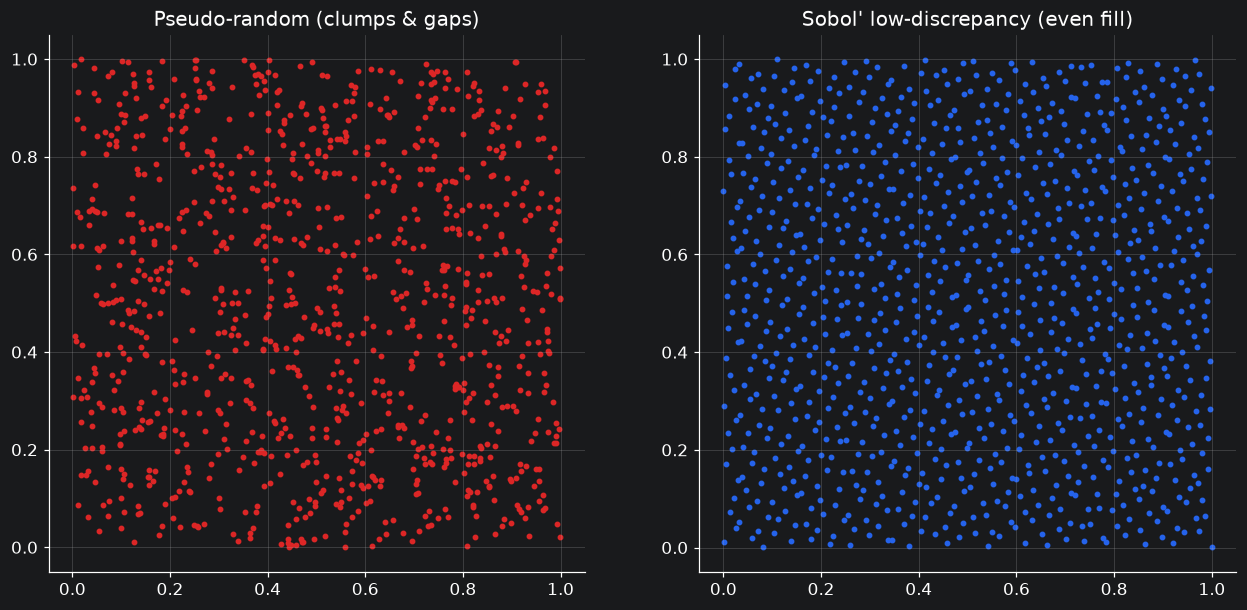

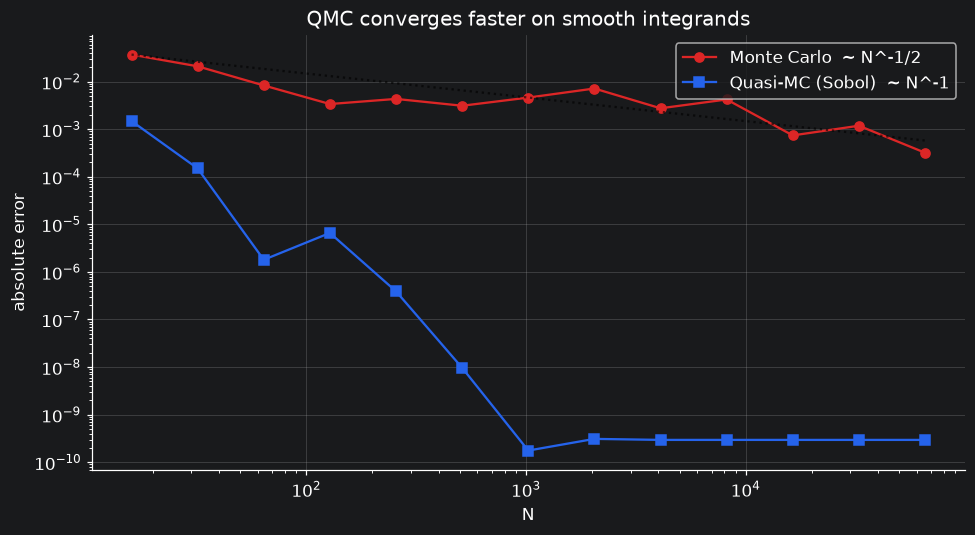

In [9]:
from scipy.stats import qmc

n = 1024
random_pts = rng.random((n, 2))
sobol_pts  = qmc.Sobol(d=2, seed=rng).random(n)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.6))
a1.scatter(*random_pts.T, s=8, color="#dc2626"); a1.set(title="Pseudo-random (clumps & gaps)", aspect="equal")
a2.scatter(*sobol_pts.T,  s=8, color="#2563eb"); a2.set(title="Sobol' low-discrepancy (even fill)", aspect="equal")
plt.tight_layout(); plt.show()

# Convergence comparison on the smooth 1-D integral of exp(-x^2) on [0,1]
from scipy.special import erf
true_val = np.sqrt(np.pi)/2*erf(1)
Ns = (2**np.arange(4, 17))
mc_err, qmc_err = [], []
for N in Ns:
    mc_err.append(abs(np.exp(-rng.random(N)**2).mean() - true_val))
    s = qmc.Sobol(d=1, seed=rng).random(N).ravel()
    qmc_err.append(abs(np.exp(-s**2).mean() - true_val))

plt.figure()
plt.loglog(Ns, mc_err, "o-", color="#dc2626", label="Monte Carlo  ~ N^-1/2")
plt.loglog(Ns, qmc_err, "s-", color="#2563eb", label="Quasi-MC (Sobol)  ~ N^-1")
plt.loglog(Ns, Ns**-0.5*mc_err[0]*Ns[0]**0.5, "k:", alpha=.6)
plt.xlabel("N"); plt.ylabel("absolute error"); plt.legend()
plt.title("QMC converges faster on smooth integrands"); plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> <i>Left:</i> pseudo-random points clump and leave gaps; Sobol&rsquo; points fill the square evenly. <i>Right:</i> that even coverage makes Quasi-MC error fall like ~1/N versus MC&rsquo;s ~1/&radic;N &mdash; nearly a full power faster on this smooth integrand.<br><b>Takeaway:</b> for smooth, moderate-dimension integrals, well-spread points beat randomness.
''')

## 8. Markov Chain Monte Carlo (MCMC)

The techniques so far need **independent** samples from the target. But in Bayesian
statistics the target is a posterior $p(\theta \mid \text{data})$ known only up to a
normalizing constant — we can't sample it directly. **MCMC** builds a *Markov chain*
whose stationary distribution **is** the target; after a burn-in the chain's states are
(correlated) samples from $p$.

### Metropolis–Hastings algorithm
Given current state $\theta$, target density $\pi$ (unnormalized OK), and a symmetric
proposal:
1. Propose $\theta' \sim q(\cdot\mid\theta)$.
2. Compute acceptance ratio $\;\alpha = \min\!\left(1,\; \dfrac{\pi(\theta')}{\pi(\theta)}\right).$
3. Accept $\theta'$ with probability $\alpha$, else stay at $\theta$.

Because only the **ratio** $\pi(\theta')/\pi(\theta)$ appears, the unknown normalizing
constant **cancels** — this is the key trick. The chain satisfies *detailed balance*
$\pi(\theta)\,P(\theta\to\theta') = \pi(\theta')\,P(\theta'\to\theta)$, which guarantees
$\pi$ is stationary.

Below: sample a "banana" (Rosenbrock) density that ordinary methods struggle with.

Acceptance rate: 32.1%   (target ~ 20-40% is healthy)


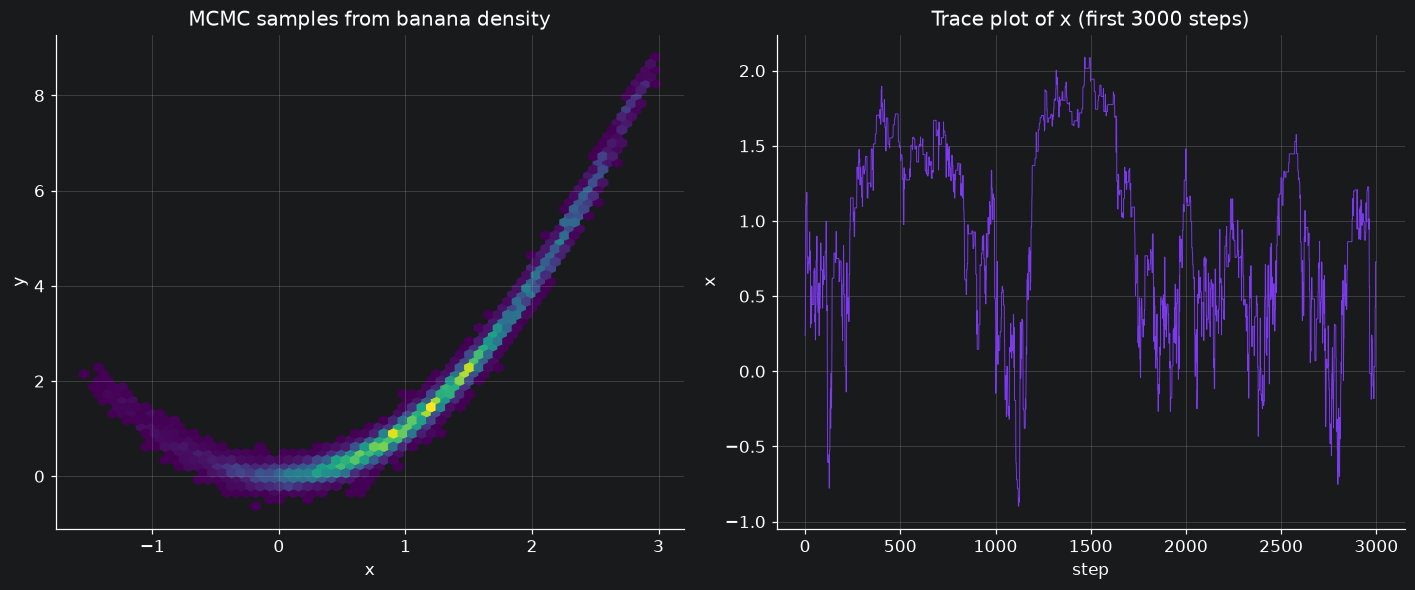

In [10]:
# Metropolis-Hastings on a 2-D banana-shaped (Rosenbrock) density.
def log_target(xy):
    x, y = xy
    return -((1 - x)**2 + 20*(y - x**2)**2)     # log of unnormalized density

n_steps, step = 60_000, 0.25
chain = np.empty((n_steps, 2))
cur = np.array([0.0, 0.0]); cur_lp = log_target(cur)
n_accept = 0
for t in range(n_steps):
    prop = cur + rng.normal(scale=step, size=2)
    prop_lp = log_target(prop)
    if np.log(rng.random()) < prop_lp - cur_lp:   # accept in log-space
        cur, cur_lp = prop, prop_lp
        n_accept += 1
    chain[t] = cur

burn = 5_000
samples = chain[burn:]
print(f"Acceptance rate: {n_accept/n_steps:.1%}   (target ~ 20-40% is healthy)")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5))
# Density of samples
a1.hexbin(samples[:,0], samples[:,1], gridsize=60, cmap="viridis", mincnt=1)
a1.set(title="MCMC samples from banana density", xlabel="x", ylabel="y")
# Trace plot of the x-coordinate (mixing diagnostic)
a2.plot(chain[:3000, 0], lw=0.6, color="#7c3aed")
a2.set(title="Trace plot of x (first 3000 steps)", xlabel="step", ylabel="x")
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> <i>Left:</i> the cloud of accepted samples traces the curved &lsquo;banana&rsquo; density &mdash; MCMC explored a shape we cannot sample directly. <i>Right:</i> the trace plot shows the chain wandering; healthy mixing looks like this fuzzy caterpillar, not long flat stretches.<br><b>Takeaway:</b> Metropolis&ndash;Hastings samples any density known only up to a constant, using just acceptance ratios min(1, &pi;&prime;/&pi;).
''')

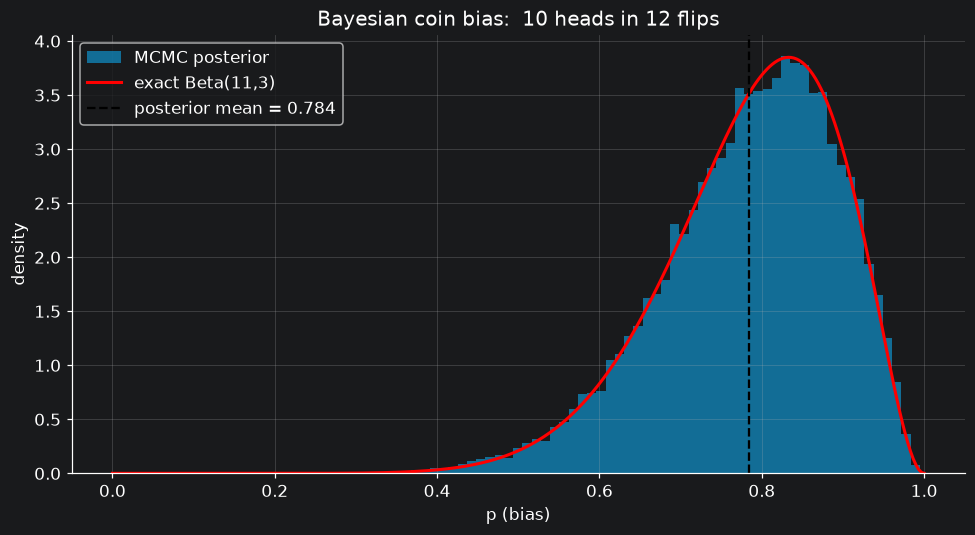

MCMC posterior mean = 0.7845   exact = 0.7857


In [11]:
# Bayesian inference with MCMC: estimate a coin's bias p from 10 heads in 12 flips.
# Prior: Uniform(0,1) = Beta(1,1).  Likelihood: Binomial.
# Posterior is analytically Beta(1+heads, 1+tails) -- so we can CHECK the MCMC.
heads, tails = 10, 2

def log_post(p):
    if p <= 0 or p >= 1: return -np.inf
    return heads*np.log(p) + tails*np.log(1-p)    # + const

n = 40_000; chain = np.empty(n); cur = 0.5; cur_lp = log_post(cur)
for t in range(n):
    prop = cur + rng.normal(scale=0.1)
    lp = log_post(prop)
    if np.log(rng.random()) < lp - cur_lp:
        cur, cur_lp = prop, lp
    chain[t] = cur
post = chain[2000:]

plt.figure()
plt.hist(post, bins=60, density=True, color="#0ea5e9", alpha=0.6, label="MCMC posterior")
pp = np.linspace(0,1,300)
plt.plot(pp, st.beta(1+heads, 1+tails).pdf(pp), "r", lw=2, label="exact Beta(11,3)")
plt.axvline(post.mean(), color="k", ls="--", label=f"posterior mean = {post.mean():.3f}")
plt.title("Bayesian coin bias:  10 heads in 12 flips"); plt.xlabel("p (bias)"); plt.ylabel("density")
plt.legend(); plt.tight_layout(); plt.show()
print(f"MCMC posterior mean = {post.mean():.4f}   exact = {(1+heads)/(2+heads+tails):.4f}")

explain(r'''
<b>How to read this.</b> The histogram is the MCMC-sampled posterior for the coin&rsquo;s bias after 10 heads in 12 flips; the red curve is the exact Beta(11,3) posterior &mdash; they coincide. The dashed line is the posterior mean (~0.79).<br><b>Takeaway:</b> MCMC recovers the correct Bayesian answer; here we can verify it because a closed form happens to exist.
''')

## 9. Applications

### 9.1 Finance — pricing a European call option

Under the risk-neutral measure, a stock follows **Geometric Brownian Motion**:

$$S_T = S_0 \exp\!\left[\Big(r - \tfrac{1}{2}\sigma^2\Big)T + \sigma\sqrt{T}\,Z\right],
\qquad Z\sim\mathcal{N}(0,1).$$

A European call paying $\max(S_T - K, 0)$ is priced as the **discounted expected payoff**:

$$C = e^{-rT}\,\mathbb{E}\big[\max(S_T-K,0)\big].$$

We estimate this by simulating many terminal prices and averaging — then compare against
the closed-form **Black–Scholes** price to confirm MC is right. MC's real power: it
prices *path-dependent* and *high-dimensional* options where no formula exists.

Monte Carlo call price = 8.0275  +/- 0.0258  (95% CI)
Black-Scholes formula  = 8.0214


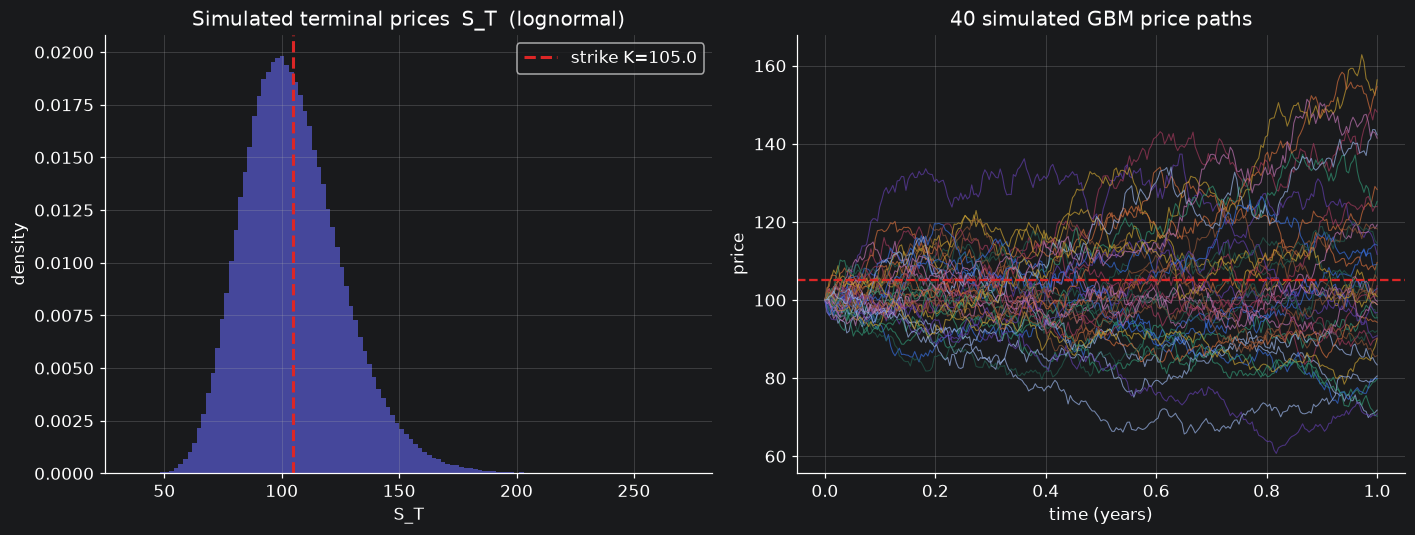

In [12]:
S0, K, r, sigma, T = 100.0, 105.0, 0.05, 0.20, 1.0

def bs_call(S0, K, r, sigma, T):
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T)/(sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S0*st.norm.cdf(d1) - K*np.exp(-r*T)*st.norm.cdf(d2)

N = 1_000_000
Z = rng.standard_normal(N)
ST = S0*np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
payoff = np.maximum(ST - K, 0.0)
disc = np.exp(-r*T)
mc_price = disc*payoff.mean()
mc_se    = disc*payoff.std(ddof=1)/np.sqrt(N)
analytic = bs_call(S0, K, r, sigma, T)

print(f"Monte Carlo call price = {mc_price:.4f}  +/- {1.96*mc_se:.4f}  (95% CI)")
print(f"Black-Scholes formula  = {analytic:.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
# Simulated terminal price distribution
a1.hist(ST, bins=120, density=True, color="#6366f1", alpha=0.6)
a1.axvline(K, color="#dc2626", ls="--", lw=2, label=f"strike K={K}")
a1.set(title="Simulated terminal prices  S_T  (lognormal)", xlabel="S_T", ylabel="density"); a1.legend()
# Sample price paths for intuition
steps = 252; dt = T/steps
paths = np.zeros((40, steps+1)); paths[:,0]=S0
for t in range(1, steps+1):
    paths[:,t] = paths[:,t-1]*np.exp((r-0.5*sigma**2)*dt + sigma*np.sqrt(dt)*rng.standard_normal(40))
a2.plot(np.linspace(0,T,steps+1), paths.T, lw=0.7, alpha=0.7)
a2.axhline(K, color="#dc2626", ls="--", lw=1.5)
a2.set(title="40 simulated GBM price paths", xlabel="time (years)", ylabel="price")
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> <i>Left:</i> simulated terminal stock prices S(T) (lognormal under GBM); only the mass right of the strike K pays off. <i>Right:</i> 40 simulated price paths feeding that distribution. The option price is the discounted average payoff, matching Black&ndash;Scholes.<br><b>Takeaway:</b> MC prices derivatives by simulating the underlying &mdash; and still works for exotic options with no formula.
''')

### 9.2 Risk — Value-at-Risk (VaR) of a portfolio

**Value-at-Risk** at level $\alpha$ is the loss threshold exceeded only with probability
$1-\alpha$: the $\alpha$-quantile of the loss distribution. **Conditional VaR** (Expected
Shortfall) is the *average* loss *beyond* VaR. MC handles arbitrary correlated assets and
non-linear positions where analytic VaR fails. We simulate a 3-asset portfolio with a
correlation structure.

99% 1-day VaR  = $25,002   (lose more than this 1% of days)
99% 1-day CVaR = $28,750  (average loss on those worst days)


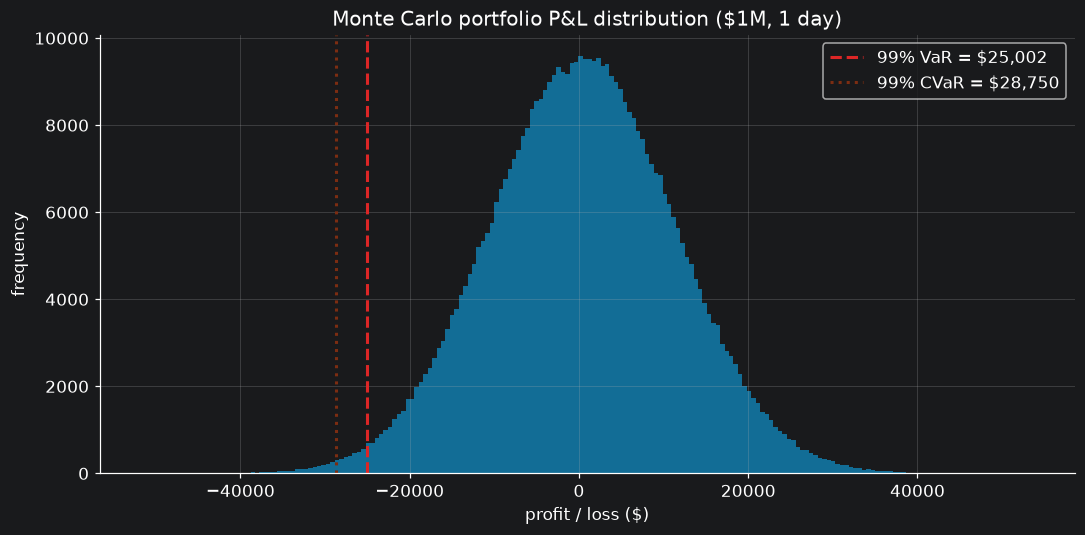

In [13]:
# 3 correlated assets, 1-day horizon, simulate portfolio P&L.
weights = np.array([0.5, 0.3, 0.2])
mu = np.array([0.0004, 0.0006, 0.0003])            # daily expected returns
vol = np.array([0.012, 0.020, 0.008])              # daily vols
corr = np.array([[1.0, 0.5, 0.2],
                 [0.5, 1.0, 0.3],
                 [0.2, 0.3, 1.0]])
cov = np.outer(vol, vol) * corr

N = 500_000
sims = rng.multivariate_normal(mu, cov, size=N)    # daily returns per asset
port_ret = sims @ weights                          # portfolio return
port_pnl = port_ret * 1_000_000                    # $1M portfolio

alpha = 0.99
VaR  = -np.percentile(port_pnl, (1-alpha)*100)
CVaR = -port_pnl[port_pnl <= -VaR].mean()
print(f"99% 1-day VaR  = ${VaR:,.0f}   (lose more than this 1% of days)")
print(f"99% 1-day CVaR = ${CVaR:,.0f}  (average loss on those worst days)")

plt.figure(figsize=(10,5))
plt.hist(port_pnl, bins=200, color="#0ea5e9", alpha=0.6)
plt.axvline(-VaR, color="#dc2626", ls="--", lw=2, label=f"99% VaR = ${VaR:,.0f}")
plt.axvline(-CVaR, color="#7c2d12", ls=":", lw=2, label=f"99% CVaR = ${CVaR:,.0f}")
plt.title("Monte Carlo portfolio P&L distribution ($1M, 1 day)")
plt.xlabel("profit / loss ($)"); plt.ylabel("frequency"); plt.legend()
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> The histogram is 500,000 simulated one-day portfolio P&amp;Ls. <b>VaR</b> (dashed) is the loss exceeded only 1% of days; <b>CVaR</b> (dotted) is the average loss on those worst 1% of days.<br><b>Takeaway:</b> MC measures tail risk for arbitrary correlated portfolios where analytic formulas break down.
''')

### 9.3 Physics — random walks & diffusion

Monte Carlo's birthplace. A **random walk** is the discrete model of diffusion /
Brownian motion. A key result: after $n$ steps the expected squared distance from the
origin grows **linearly**, $\mathbb{E}[R^2] = n$ (in 2-D with unit steps), so the typical
distance scales as $\sqrt{n}$ — the same $\sqrt{N}$ law underlying MC error.

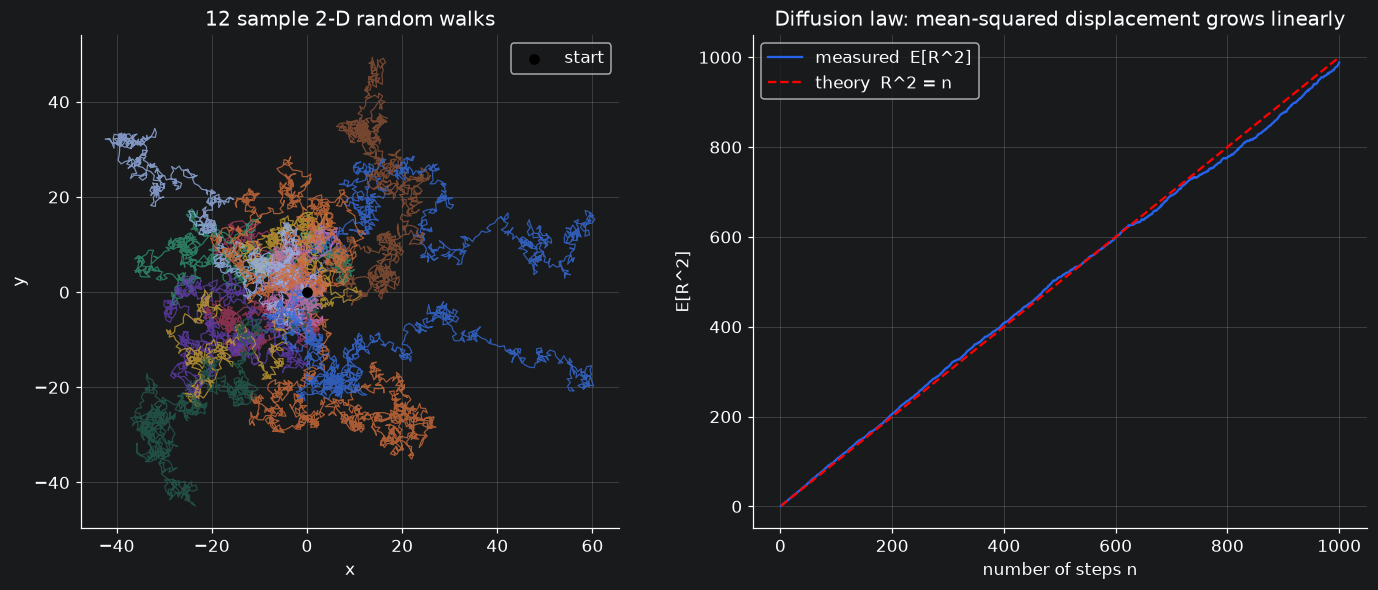

In [14]:
n_walkers, n_steps = 2000, 1000
# 2-D walk: each step is a unit vector in a random direction.
angles = rng.uniform(0, 2*np.pi, size=(n_walkers, n_steps))
steps = np.stack([np.cos(angles), np.sin(angles)], axis=-1)
pos = np.cumsum(steps, axis=1)                       # positions over time

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5))
for i in range(12):
    a1.plot(pos[i,:,0], pos[i,:,1], lw=0.8, alpha=0.8)
a1.scatter([0],[0], color="k", zorder=5, label="start")
a1.set(title="12 sample 2-D random walks", xlabel="x", ylabel="y", aspect="equal"); a1.legend()

# Mean squared displacement vs steps -> should be linear with slope ~1
msd = (pos**2).sum(axis=-1).mean(axis=0)
a2.plot(np.arange(1, n_steps+1), msd, color="#2563eb", label="measured  E[R^2]")
a2.plot(np.arange(1, n_steps+1), np.arange(1, n_steps+1), "r--", label="theory  R^2 = n")
a2.set(title="Diffusion law: mean-squared displacement grows linearly",
       xlabel="number of steps n", ylabel="E[R^2]"); a2.legend()
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> <i>Left:</i> 12 random walks spreading from the origin. <i>Right:</i> averaged over 2,000 walkers, mean-squared displacement grows linearly with steps (measured &asymp; theory line).<br><b>Takeaway:</b> typical distance scales as &radic;n &mdash; the diffusion law, and the same square-root behaviour behind MC error itself.
''')

### 9.4 Optimization — simulated annealing

A Monte Carlo *optimizer*. To minimize a rugged cost $E(x)$, accept downhill moves
always and uphill moves with probability $e^{-\Delta E / T}$ (the **Metropolis
criterion**). Slowly lowering the "temperature" $T$ lets the search escape local minima
early, then settle into a global one. We minimize a deceptive 1-D function with many
local traps.

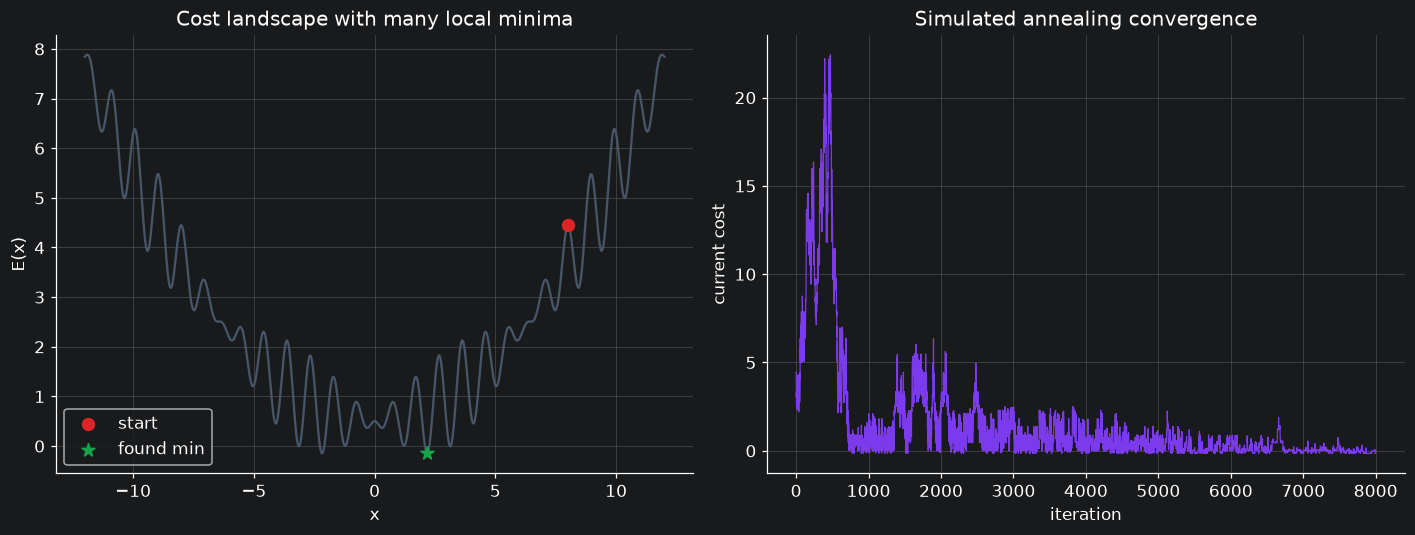

Found x = 2.174,  E = -0.1489   (global min ~ -0.1489)


In [15]:
# Cost with many local minima; global min near x ~ where the trend bottoms out.
E = lambda x: x**2/20 + np.sin(3*x)**2 + 0.5*np.cos(7*x)

x = 8.0                       # bad starting point
T = 5.0
hist = [x]
for it in range(8000):
    T *= 0.9995               # geometric cooling schedule
    x_new = x + rng.normal(scale=0.5)
    dE = E(x_new) - E(x)
    if dE < 0 or rng.random() < np.exp(-dE/max(T,1e-9)):
        x = x_new
    hist.append(x)
hist = np.array(hist)

xx = np.linspace(-12, 12, 1000)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
a1.plot(xx, E(xx), color="#475569")
a1.scatter(hist[0], E(hist[0]), color="#dc2626", zorder=5, s=60, label="start")
a1.scatter(hist[-1], E(hist[-1]), color="#16a34a", zorder=5, s=80, marker="*", label="found min")
a1.set(title="Cost landscape with many local minima", xlabel="x", ylabel="E(x)"); a1.legend()
a2.plot(E(hist), color="#7c3aed", lw=0.8)
a2.set(title="Simulated annealing convergence", xlabel="iteration", ylabel="current cost")
plt.tight_layout(); plt.show()
print(f"Found x = {hist[-1]:.3f},  E = {E(hist[-1]):.4f}   (global min ~ {E(xx).min():.4f})")

explain(r'''
<b>How to read this.</b> <i>Left:</i> a bumpy cost landscape full of local minima; the search starts at the red dot and ends at the green star near the global minimum. <i>Right:</i> the cost sometimes moves upward &mdash; accepting worse moves while &lsquo;hot&rsquo; &mdash; then settles as it cools.<br><b>Takeaway:</b> controlled randomness lets simulated annealing escape traps that greedy descent gets stuck in.
''')

## 10. Convergence diagnostics & common pitfalls

- **Always report error bars.** A MC number without a confidence interval
  $\hat\mu \pm 1.96\,\sigma/\sqrt N$ is meaningless.
- **Infinite/large variance ⇒ failure.** The CLT needs $\sigma^2 < \infty$. Heavy-tailed
  integrands (e.g. estimating $\mathbb{E}[1/X]$ near 0) converge painfully or not at all.
- **Rare events need importance sampling.** Naive MC wastes ~all samples where the
  payoff is zero (§6.3).
- **MCMC needs burn-in and mixing checks.** Discard initial samples; watch trace plots,
  autocorrelation, and the $\hat R$ statistic across multiple chains. Correlated samples
  inflate the *effective* sample size downward.
- **Reproducibility:** always seed your generator (we used `np.random.default_rng(42)`).
- **Vectorize.** Loop-free NumPy is often 100× faster than Python loops; for truly heavy
  workloads parallelize across cores.

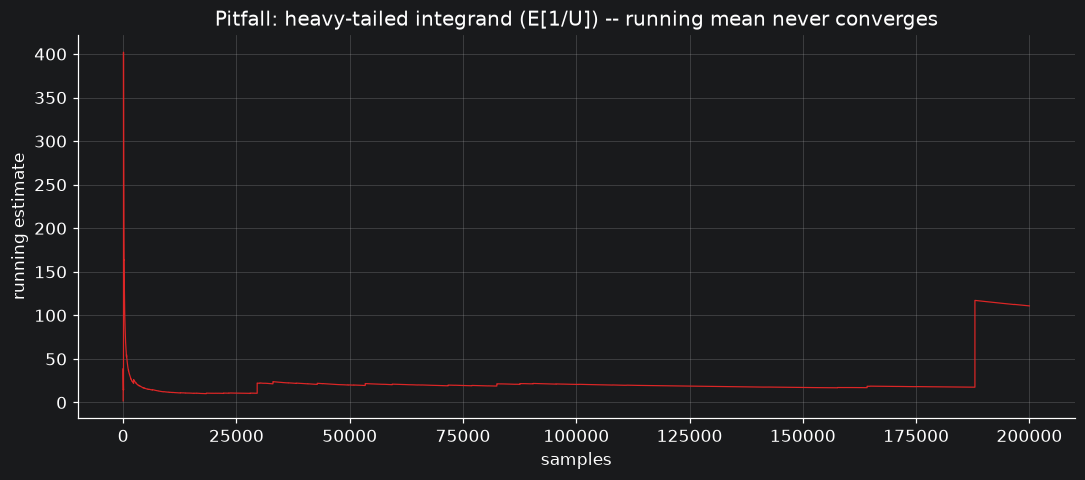

Each spike is one unlucky tiny U producing a huge 1/U. The mean E[1/U] itself diverges.


In [16]:
# Pitfall demo: an estimator with (near-)infinite variance refuses to converge.
# Estimate E[1/U] for U ~ Uniform(0,1) -- the true integral diverges, so the
# running mean never settles (notice the violent jumps when a tiny U appears).
N = 200_000
u = rng.random(N)
running = np.cumsum(1/u)/np.arange(1, N+1)

plt.figure(figsize=(10,4.5))
plt.plot(running, color="#dc2626", lw=0.8)
plt.title("Pitfall: heavy-tailed integrand (E[1/U]) -- running mean never converges")
plt.xlabel("samples"); plt.ylabel("running estimate")
plt.tight_layout(); plt.show()
print("Each spike is one unlucky tiny U producing a huge 1/U. The mean E[1/U] itself diverges.")

explain(r'''
<b>How to read this.</b> This running mean of 1/U never settles &mdash; each spike is one unlucky tiny U producing a huge value. The expectation E[1/U] diverges (infinite mean), so the LLN and CLT do not apply.<br><b>Takeaway:</b> Monte&nbsp;Carlo fails silently on heavy-tailed integrands. Always check the variance is finite and report error bars.
''')

## 11. Cheat sheet & further reading

| Technique | Use it when | Key formula |
|---|---|---|
| **Plain MC** | any expectation/integral | $\hat\mu = \frac1N\sum f(X_i)$ |
| **Inverse transform** | CDF is invertible | $X=F^{-1}(U)$ |
| **Rejection sampling** | can bound $p \le Mq$ | accept w.p. $p/(Mq)$ |
| **Antithetic variates** | monotone integrand | use $U$ and $1-U$ |
| **Control variates** | correlated known-mean helper | $\bar f - c(\bar h - \mathbb E h)$ |
| **Importance sampling** | rare events / tails | weight by $p/q$ |
| **Stratified sampling** | structured domain | sample per stratum |
| **Quasi-MC** | smooth, moderate $d$ | Sobol'/Halton, $\mathcal O(N^{-1})$ |
| **MCMC (Metropolis–Hastings)** | unnormalized target / Bayesian | accept w.p. $\min(1,\pi'/\pi)$ |
| **Simulated annealing** | global optimization | accept uphill w.p. $e^{-\Delta E/T}$ |

**The one law to remember:** Monte Carlo error is $\dfrac{\sigma}{\sqrt N}$ —
*dimension-independent*, which is why it conquers high-dimensional problems that defeat
every grid-based method.

### References
- Robert & Casella, *Monte Carlo Statistical Methods* (2004)
- Glasserman, *Monte Carlo Methods in Financial Engineering* (2003)
- Owen, *Monte Carlo theory, methods and examples* (free online, 2013)
- Metropolis & Ulam, "The Monte Carlo Method", *JASA* (1949)